# Project 1: Wealth Inequality in Denmark
Starter notebook. Add your names, code and interpretations. Keep your simulation module (.py) beside this notebook.

**Group name:**  
**Members:**

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

## Download function
`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [1]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-801501
1,P1,006,1829,2024,-437821
2,P1,006,3039,2024,-1097902
3,P1,006,4049,2024,-1128378
4,P1,006,5059,2024,-968947


## 1.1   Download and Read the Tables
Tasks and hints: PDF Section 1.1.

In [ ]:
# 1.1.1 Downloading and reading the tables

# Downloading FORMUE16: Wealth percentiles
percentiles = download('FORMUE16', PERCENTIL='*', **settings)

# Downloading FORMUE15: Wealth brackets and population counts
counts = download('FORMUE15', FORMUE='*', DEFINITION='D20', **settings)


In [3]:
# 1.1.2 Inspecting the rows of both tables
print("FORMUE16:")
display(percentiles.head())

print("FORMUE15:")
display(counts.head())

# Inspecting age groups, percentiles and wealth brackets
print("Age groups:", percentiles["ALDER"].unique())
print("Percentiles:", percentiles["PERCENTIL"].unique())
print("Wealth brackets:", counts["FORMUE"].unique())

# Identify age group codes and labels from FORMUE15
url = "https://api.statbank.dk/v1/tableinfo/FORMUE15"

response = requests.get(
    url,
    params={"lang": "en", "format": "JSON"}
)
response.raise_for_status()

# Display age group codes and descriptions
for variable in response.json()["variables"]:
    if variable["id"] == "ALDER":
        for value in variable["values"]:
            print(value["id"], ":", value["text"])

FORMUE16:


,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-801501
1,P1,006,1829,2024,-437821
2,P1,006,3039,2024,-1097902
3,P1,006,4049,2024,-1128378
4,P1,006,5059,2024,-968947


FORMUE15:


,FORMUE,DEFINITION,PRISENHED,ALDER,TID,value
0,0000M10,D20,006,1802,2024,35488
1,0000M10,D20,006,1829,2024,2199
2,0000M10,D20,006,3039,2024,9488
3,0000M10,D20,006,4049,2024,8438
4,0000M10,D20,006,5059,2024,7737


Age groups: <ArrowStringArray>
['1802', '1829', '3039', '4049', '5059', '6069', '7079', '8089', '9099']
Length: 9, dtype: str
Percentiles: <ArrowStringArray>
[ 'P1',  'P2',  'P3',  'P4',  'P5',  'P6',  'P7',  'P8',  'P9', 'P10', 'P11',
 'P12', 'P13', 'P14', 'P15', 'P16', 'P17', 'P18', 'P19', 'P20', 'P21', 'P22',
 'P23', 'P24', 'P25', 'P26', 'P27', 'P28', 'P29', 'P30', 'P31', 'P32', 'P33',
 'P34', 'P35', 'P36', 'P37', 'P38', 'P39', 'P40', 'P41', 'P42', 'P43', 'P44',
 'P45', 'P46', 'P47', 'P48', 'P49', 'P50', 'P51', 'P52', 'P53', 'P54', 'P55',
 'P56', 'P57', 'P58', 'P59', 'P60', 'P61', 'P62', 'P63', 'P64', 'P65', 'P66',
 'P67', 'P68', 'P69', 'P70', 'P71', 'P72', 'P73', 'P74', 'P75', 'P76', 'P77',
 'P78', 'P79', 'P80', 'P81', 'P82', 'P83', 'P84', 'P85', 'P86', 'P87', 'P88',
 'P89', 'P90', 'P91', 'P92', 'P93', 'P94', 'P95', 'P96', 'P97', 'P98', 'P99']
Length: 99, dtype: str
Wealth brackets: <ArrowStringArray>
['0000M10', 'M100M05', 'M050000', '0000005', '0050010', '0100015', '0150020',
 '0

The aggregate age category for 18 years old and over is '1802'.
The FORMUE16 dataset contains 99 wealth percentiles for each age category. For the following analysis we contiue by excluding the adult category from the age-specific data and keep the eight individual age groups. 

In [4]:
# Separating all adults (18+) from the eight age groups

# FORMUE16: Separating wealth percentiles
percentiles_all = percentiles[percentiles["ALDER"] == "1802"].copy()
percentiles_age = percentiles[percentiles["ALDER"] != "1802"].copy()

# FORMUE15: Separating population counts for all adults
counts_all = counts[counts["ALDER"] == "1802"].copy()
counts_age = counts[counts["ALDER"] != "1802"].copy()

# Checking that both datasets have eight age groups
print("Age groups in FORMUE16:", percentiles_age["ALDER"].nunique())
print("Age groups in FORMUE15:", counts_age["ALDER"].nunique())

Age groups in FORMUE16: 8
Age groups in FORMUE15: 8


## 1.2   Plot the Age Profiles
Tasks and hints: PDF Section 1.2.

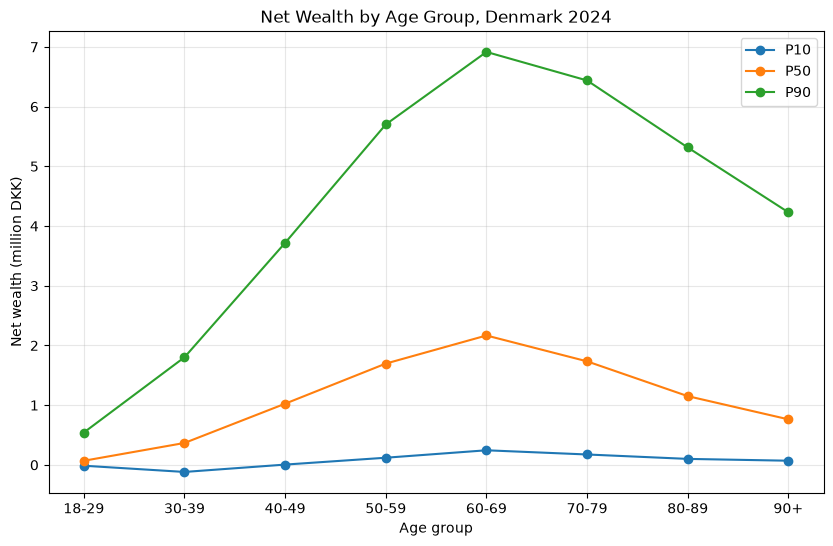

In [ ]:

# Exercise 1.2.1 Plot the Age Profiles

# Converting percentile codes from strings to integers
percentiles_age["percentile"] = (
    percentiles_age["PERCENTIL"].str.replace("P", "").astype(int)
)

# Reshaping data: one row per age group and one column per percentile
wealth_age = percentiles_age.pivot_table(
    index="ALDER",
    columns="percentile",
    values="value"
)

# Selecting P10, P50 and P90
wealth_profile = wealth_age[[10, 50, 90]].copy()

# Defining age group labels
age_names = {
    "1829": "18-29",
    "3039": "30-39",
    "4049": "40-49",
    "5059": "50-59",
    "6069": "60-69",
    "7079": "70-79",
    "8089": "80-89",
    "9099": "90+"
}

# Ensuring that the age groups are ordered correctly
wealth_profile = wealth_profile.reindex(age_names.keys())

# Plotting the age profiles of wealth percentiles
fig, ax = plt.subplots(figsize=(10, 6))

for p in [10, 50, 90]:
    ax.plot(
        age_labels,
        wealth_profile[p] / 1_000_000,
        marker="o",
        label=f"P{p}"
    )

ax.set_xlabel("Age group")
ax.set_ylabel("Net wealth (million DKK)")
ax.set_title("Net Wealth by Age Group, Denmark 2024")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

**Exercise 1.2.1.**
The figure shows the 10th, 50th and 90th percentiles (P10, P50 and P90) of net wealth for each age group in Denmark in 2024. For example, a 18–29-year-old at P90, i.e. with higher net wealth than 90 percent of the other Danes in the same age group, has a net wealth of around 0.5 million DKK. A 60–69-year-old at P90 has a net wealth of approximately 7 million DKK.

The differences between the percentiles become larger from age group 18–29 up to 60–69 and then smaller again in the older age groups. This applies to the difference between P10 and P50, between P50 and P90, and between P10 and P90. Since the data are a cross-section from 2024, the figure compares different people in different age groups, not the same people as they get older.

In [ ]:
# Exercise 1.2.2 Calculating age gaps
wealth_profile["upper_gap"] = wealth_profile[90] - wealth_profile[50]
wealth_profile["lower_gap"] = wealth_profile[50] - wealth_profile[10]

wealth_profile_display = wealth_profile.rename(index=age_names)

display(
    wealth_profile_display.rename(columns={
        10: "P10",
        50: "P50",
        90: "P90",
        "upper_gap": "Upper gap",
        "lower_gap": "Lower gap"
    }).round(0)
)

display(wealth_profile)

# Find the age group with the widest upper gap
max_age = wealth_profile["upper_gap"].idxmax()
max_gap = wealth_profile.loc[max_age, "upper_gap"]

print(f"Widest upper gap: {max_age}")
print(f"Amount: {max_gap:,.0f} DKK")

percentile,P10,P50,P90,Upper gap,Lower gap
ALDER,,,,,
18-29,-14254.0,68806.0,541878.0,473072.0,83060.0
30-39,-118420.0,366935.0,1802110.0,1435175.0,485355.0
40-49,4660.0,1024656.0,3718363.0,2693707.0,1019996.0
50-59,119753.0,1696187.0,5700964.0,4004777.0,1576434.0
60-69,244332.0,2166898.0,6915373.0,4748475.0,1922566.0
70-79,174039.0,1733634.0,6437553.0,4703919.0,1559595.0
80-89,100122.0,1151164.0,5315410.0,4164246.0,1051042.0
90+,69644.0,762475.0,4229814.0,3467339.0,692831.0


percentile,10,50,90,upper_gap,lower_gap
ALDER,,,,,
1829,-14254.0,68806.0,541878.0,473072.0,83060.0
3039,-118420.0,366935.0,1802110.0,1435175.0,485355.0
4049,4660.0,1024656.0,3718363.0,2693707.0,1019996.0
5059,119753.0,1696187.0,5700964.0,4004777.0,1576434.0
6069,244332.0,2166898.0,6915373.0,4748475.0,1922566.0
7079,174039.0,1733634.0,6437553.0,4703919.0,1559595.0
8089,100122.0,1151164.0,5315410.0,4164246.0,1051042.0
9099,69644.0,762475.0,4229814.0,3467339.0,692831.0


Widest upper gap: 6069
Amount: 4,748,475 DKK


**Interpretation.** The largest upper wealth gap is observed in the age group 60-69, where the difference between P90 and P50 is approximately 4.74 million DKK. This indicates that there are larger wealth differences in the upper half of the wealth distribution for this age group.

In [ ]:
# Exercise 1.2.3 Identifying age groups with negative P10

negative_p10 = wealth_profile[wealth_profile[10] < 0]

print("Age groups with negative P10:")
print(negative_p10.index.tolist())


Age groups with negative P10:
['1829', '3039']


**Exercise 1.2.3 - Interpretation**
P10 is negative for the 18–29-year-olds and the 30–39-year-olds. This means that at least 10 percent of the people in these age groups have a negative net wealth, i.e. their debt is larger than their assets.

One economic reason why young adults are more likely than older adults to have more debt than assets is that they have recently taken on large loans, for example student loans or a mortgage for their first home, while they have not yet had time to build up assets through savings, pension contributions and paying off debt. Older adults have had many more years to save and pay down their loans, so their assets are more likely to exceed their debt

## 1.3   Who Has Negative Net Wealth?
Tasks and hints: PDF Section 1.3.

**Interpretation.** Write your answer here.

## 2.1   Give Everybody Their Age-Group Median
Tasks and hints: PDF Section 2.1.

In [34]:
# Import and reload the simulation function
import importlib
import simulation

importlib.reload(simulation)

from simulation import simulate_wealth

In [38]:
# Exercise 2.1.1

# Calculating the total number of adults in each group.
age_counts = counts_age.groupby("ALDER")["value"].sum()

# Making sure that the age groups are ordered correctly as in Exercise 1
age_counts = age_counts.reindex(age_names.keys())

# Calculating population shares for each age group
age_shares = age_counts / age_counts.sum()

# Displaying the population shares
display(age_shares.rename(index=age_names))

# Checking that the shares sum to one
print("Sum of population shares:", age_shares.sum())



ALDER
18-29    0.191135
30-39    0.161569
40-49    0.145941
50-59    0.165322
60-69    0.146281
70-79    0.119812
80-89    0.060178
90+      0.009762
Name: value, dtype: float64

Sum of population shares: 1.0


**Exercise 2.1.1**

The largest age group is 18-29, which is approximately 19.1% of the adult population, while individuals aged 90+ is the smallest group and only accounts 0.9%

In [41]:
# Exercise 2.1.2 - Simulating age groups

# Finding the median wealth (P50) in each age group
medians = wealth_profile[50].to_numpy()

# Simulating 10,000 adults based on population shares
age_sim, wealth_sim = simulate_wealth(
    age_shares=age_shares.to_numpy(),
    medians=medians,
    seed=42
)

# Checking the total number of simulated adults
print("Number of simulated adults:", len(age_sim))

# Number of simulated adults in each age group
simulated_counts = pd.Series(age_sim).value_counts().reindex(range(8), fill_value=0)
simulated_counts.index = list(age_names.values())

display(simulated_counts)

Number of simulated adults: 30000


18-29    5701
30-39    4886
40-49    4296
50-59    4974
60-69    4463
70-79    3602
80-89    1750
90+       328
Name: count, dtype: int64

**Interpretation.** The simulation has assigned the 10.000 adults to the eight age groups based on the observed population shares. Like the observed age distribution for the Danish population, we have that the largest simulated age group is therefore 18-29 year olds with 19.42% of the total simulated population. The smallest group is 90+ which makes up 1.10% of the population.  

In [43]:
# Exercise 2.1.3 - Assigning median wealth to simulated adults

# Displaying the age group and wealth of the first 10 simulated adults
simulated_population = pd.DataFrame({
    "Age group": [list(age_names.values())[a] for a in age_sim],
    "Wealth (DKK)": wealth_sim
})

display(simulated_population.head(10))

# Calculating simulated age shares
simulated_shares = simulated_counts / len(age_sim)

# Comparing published and simulated age shares
age_comparison = pd.DataFrame({
    "Published share (%)": age_shares.rename(index=age_names) * 100,
    "Simulated share (%)": simulated_shares * 100
})

# Calculating differences in percentage points
age_comparison["Difference (pp)"] = (
    age_comparison["Simulated share (%)"]
    - age_comparison["Published share (%)"]
)

display(age_comparison.round(2))

,Age group,Wealth (DKK)
0,60-69,2166898.0
1,40-49,1024656.0
2,70-79,1733634.0
3,60-69,2166898.0
4,18-29,68806.0
5,80-89,1151164.0
6,60-69,2166898.0
7,60-69,2166898.0
8,18-29,68806.0
9,40-49,1024656.0


,Published share (%),Simulated share (%),Difference (pp)
18-29,19.11,19.00,-0.11
30-39,16.16,16.29,0.13
40-49,14.59,14.32,-0.27
50-59,16.53,16.58,0.05
60-69,14.63,14.88,0.25
70-79,11.98,12.01,0.03
80-89,6.02,5.83,-0.18
90+,0.98,1.09,0.12


**Interpretation:**
When each simulated adult is assigned the median wealth (P50) in their age group, individuals within the same age group have the same amount of wealth. For example, individuals in the age group 60-69 are assigned to have a wealth of 2.166.898 DKK, while the individuals in the agroup 18-29 have a wealth of 68.806 DKK. The wealth inequality in this simulated economy is therefore only due to differences in the median wealth across age groups.

The simulated age shares differ a little bit from the published share. The largest deviation is observed for the age group 50-59 with a deviation of 0.50 percentage points. The small differences between the published and simulated shares arise from random sampling variation, because the published population shares are used as probabilities and not fixed proportions.

According to the law of large numbers, the simulated shares converge towards the published shares as the number of similated adults increases.

## 2.2   Allow Wealth to Vary Within Each Age Group
Tasks and hints: PDF Section 2.2.

## 2.3   Compare Both Economies with Denmark
Tasks and hints: PDF Section 2.3.

**Interpretation.** Write your answer here.

## 2.4   An Older Denmark
Tasks and hints: PDF Section 2.4.

**Interpretation.** Write your answer here.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).